# 09 — Grad-CAM Explainability
**Retinopathy Detection System**

This notebook generates Grad-CAM visualizations for the optimized EfficientNetB3 + MobileNetV2 hybrid model. It creates separate heatmaps for both feature-extraction branches, overlays them on retinal images, and saves correct and incorrect validation examples.

The latest optimized validation accuracy was 78.17%. Class 3 remains the weakest class by F1-score, followed by classes 1 and 4. Grad-CAM is an explanation aid, not proof of medical localization or clinical validity.

Run cells in order. The model is loaded with `compile=False` because Notebook 08 used a custom focal-loss function. No model is retrained or overwritten.

## 1. Imports

In [1]:
import os, json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import cv2
from sklearn.metrics import accuracy_score

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

TensorFlow: 2.16.1
GPU: []


## 2. Paths and load optimized hybrid model

In [2]:
PROJECT_ROOT = Path(r"S:\ISP")
DATA_ROOT = PROJECT_ROOT / "data"
MODEL_DIR = DATA_ROOT / "processed" / "models"
RESULT_DIR = DATA_ROOT / "processed" / "results"
GRADCAM_DIR = RESULT_DIR / "gradcam"
GRADCAM_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "hybrid_optimized_focal.keras"
VAL_SPLIT = RESULT_DIR / "efficientnetb3_validation_split.csv"
for p in [MODEL_PATH, VAL_SPLIT]:
    if not p.exists():
        raise FileNotFoundError(f"Required file not found: {p}")

csvs = [p for p in (DATA_ROOT / "raw").rglob("train.csv") if "aptos" in str(p).lower()]
if not csvs:
    raise FileNotFoundError("APTOS train.csv not found under S:/ISP/data/raw.")
DATASET_DIR = csvs[0].parent
IMAGE_DIR = DATASET_DIR / "train_images"
if not IMAGE_DIR.exists():
    raise FileNotFoundError(f"Image directory not found: {IMAGE_DIR}")

# compile=False avoids deserializing the custom focal-loss function from Notebook 08.
model = tf.keras.models.load_model(MODEL_PATH, compile=False)
print("Loaded:", MODEL_PATH)
print("Input:", model.input_shape, "| Output:", model.output_shape)
print("Grad-CAM folder:", GRADCAM_DIR)

Loaded: S:\ISP\data\processed\models\hybrid_optimized_focal.keras
Input: (None, 300, 300, 3) | Output: (None, 5)
Grad-CAM folder: S:\ISP\data\processed\results\gradcam


## 3. Load validation split and reproduce predictions

In [3]:
val_df = pd.read_csv(VAL_SPLIT)
val_df["id_code"] = val_df["id_code"].astype(str)
val_df["diagnosis"] = pd.to_numeric(val_df["diagnosis"]).astype(int)
val_df["image_path"] = val_df["id_code"].apply(lambda x: str(IMAGE_DIR / f"{x}.png"))

missing = val_df.loc[~val_df.image_path.apply(os.path.isfile), "image_path"]
if len(missing):
    raise FileNotFoundError(f"{len(missing)} validation images are missing.")

IMG_SIZE = 300
AUTOTUNE = tf.data.AUTOTUNE

def load_validation_image(path, label):
    raw = tf.io.read_file(path)
    image = tf.image.decode_image(raw, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, [IMG_SIZE, IMG_SIZE])
    return tf.cast(image, tf.float32), tf.cast(label, tf.int32)

val_ds = tf.data.Dataset.from_tensor_slices((
    val_df.image_path.values, val_df.diagnosis.values.astype(np.int32)
)).map(load_validation_image, num_parallel_calls=AUTOTUNE).batch(8).prefetch(AUTOTUNE)

y_prob = model.predict(val_ds, verbose=1)
val_df["predicted"] = np.argmax(y_prob, axis=1)
val_df["confidence"] = np.max(y_prob, axis=1)
val_df["correct"] = val_df.diagnosis.to_numpy() == val_df.predicted.to_numpy()
print("Validation images:", len(val_df))
print("Reproduced accuracy:", round(accuracy_score(val_df.diagnosis, val_df.predicted)*100, 2), "%")
display(val_df[["id_code", "diagnosis", "predicted", "confidence", "correct"]].head())

92/92 ━━━━━━━━━━━━━━━━━━━━ 158s 2s/step
Validation images: 733
Reproduced accuracy: 78.17 %


,id_code,diagnosis,predicted,confidence,correct
0,6fe67fd7f5d1,0,0,0.980209,True
1,ef8c39eb9157,0,0,0.988033,True
2,61bbc11fe503,4,2,0.337808,False
3,60edda7b4871,0,0,0.996338,True
4,d30d079e6f9a,0,0,0.949012,True


## 4. Identify the nested feature extractors

In [4]:
nested_models = [layer for layer in model.layers if isinstance(layer, tf.keras.Model)]
print("Nested model names:")
for layer in nested_models:
    print(layer.name, layer.input_shape, layer.output_shape)

eff_candidates = [m for m in nested_models if "efficientnet" in m.name.lower()]
mob_candidates = [m for m in nested_models if "mobilenet" in m.name.lower()]
if not eff_candidates or not mob_candidates:
    raise ValueError("Could not identify EfficientNet and MobileNet nested models. Share the printed names.")
eff_base, mob_base = eff_candidates[0], mob_candidates[0]
print("EfficientNet branch:", eff_base.name)
print("MobileNet branch:", mob_base.name)

Nested model names:
shared_augmentation (None, 300, 300, 3) (None, 300, 300, 3)
efficientnetb3 (None, 300, 300, 3) (None, 10, 10, 1536)
mobilenetv2_1.00_224 (None, 224, 224, 3) (None, 7, 7, 1280)
EfficientNet branch: efficientnetb3
MobileNet branch: mobilenetv2_1.00_224


## 5. Locate final convolutional layers and classifier head

In [5]:
def last_conv(backbone):
    layers = [layer for layer in backbone.layers if isinstance(layer, tf.keras.layers.Conv2D)]
    if not layers:
        raise ValueError(f"No Conv2D layer found in {backbone.name}")
    return layers[-1]

eff_conv = last_conv(eff_base)
mob_conv = last_conv(mob_base)
print("EfficientNet Grad-CAM layer:", eff_conv.name)
print("MobileNet Grad-CAM layer:", mob_conv.name)

eff_grad_model = tf.keras.Model(eff_base.input, [eff_conv.output, eff_base.output])
mob_grad_model = tf.keras.Model(mob_base.input, [mob_conv.output, mob_base.output])

fusion_layer = model.get_layer("feature_fusion")
classifier_head = tf.keras.Model(fusion_layer.input, model.output)
eff_pool = model.get_layer("eff_global_pool")
mob_pool = model.get_layer("mobile_global_pool")
print("Grad-CAM models and classifier head created.")

EfficientNet Grad-CAM layer: top_conv
MobileNet Grad-CAM layer: Conv_1
Grad-CAM models and classifier head created.


## 6. Preprocessing helpers

In [6]:
def read_image(image_path):
    bgr = cv2.imread(str(image_path))
    if bgr is None:
        raise FileNotFoundError(f"Cannot read {image_path}")
    rgb = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
    rgb_300 = cv2.resize(rgb, (300, 300), interpolation=cv2.INTER_AREA)
    return rgb, rgb_300

def eff_input(rgb_300):
    # EfficientNetB3 Keras model contains its own rescaling.
    return tf.convert_to_tensor(rgb_300[None, ...], dtype=tf.float32)

def mob_input(rgb_300):
    # Match Notebook 07: resize the shared 300px image to 224px, then scale to -1..1.
    x = tf.image.resize(tf.convert_to_tensor(rgb_300, dtype=tf.float32), [224, 224])
    return (x / 127.5 - 1.0)[None, ...]

## 7. Grad-CAM function for either hybrid branch

In [7]:
def gradcam_heatmap(rgb_300, class_index, branch="efficientnet"):
    if branch == "efficientnet":
        grad_model = eff_grad_model
        branch_x = eff_input(rgb_300)
        pool = eff_pool
        fixed_conv, fixed_backbone = mob_grad_model(mob_input(rgb_300), training=False)
        fixed_features = mob_pool(fixed_backbone)
        branch_is_eff = True
    elif branch == "mobilenet":
        grad_model = mob_grad_model
        branch_x = mob_input(rgb_300)
        pool = mob_pool
        fixed_conv, fixed_backbone = eff_grad_model(eff_input(rgb_300), training=False)
        fixed_features = eff_pool(fixed_backbone)
        branch_is_eff = False
    else:
        raise ValueError("branch must be 'efficientnet' or 'mobilenet'")

    with tf.GradientTape() as tape:
        conv_features, backbone_features = grad_model(branch_x, training=False)
        pooled = pool(backbone_features)
        if branch_is_eff:
            scores = classifier_head([pooled, fixed_features], training=False)
        else:
            scores = classifier_head([fixed_features, pooled], training=False)
        class_score = scores[:, class_index]

    grads = tape.gradient(class_score, conv_features)
    if grads is None:
        raise RuntimeError(f"Gradients unavailable for {branch} branch.")
    weights = tf.reduce_mean(grads, axis=(1, 2))
    conv_features = conv_features[0]
    weights = weights[0]
    heatmap = tf.reduce_sum(conv_features * weights[None, None, :], axis=-1)
    heatmap = tf.maximum(heatmap, 0)
    max_value = tf.reduce_max(heatmap)
    heatmap = tf.where(max_value > 0, heatmap / (max_value + 1e-8), heatmap)
    return heatmap.numpy()

## 8. Overlay and save heatmap panels

In [8]:
def overlay_heatmap(rgb, heatmap, alpha=0.38):
    h, w = rgb.shape[:2]
    heatmap = cv2.resize(heatmap, (w, h))
    heatmap_u8 = np.uint8(255 * np.clip(heatmap, 0, 1))
    colored = cv2.applyColorMap(heatmap_u8, cv2.COLORMAP_JET)
    colored = cv2.cvtColor(colored, cv2.COLOR_BGR2RGB)
    overlay = cv2.addWeighted(rgb.astype(np.uint8), 1-alpha, colored, alpha, 0)
    return overlay

def save_gradcam_panel(row):
    rgb, rgb_300 = read_image(row.image_path)
    pred = int(row.predicted)
    eff_map = gradcam_heatmap(rgb_300, pred, "efficientnet")
    mob_map = gradcam_heatmap(rgb_300, pred, "mobilenet")
    eff_overlay = overlay_heatmap(rgb, eff_map)
    mob_overlay = overlay_heatmap(rgb, mob_map)

    status = "correct" if bool(row.correct) else "incorrect"
    filename = f"{row.id_code}_actual{int(row.diagnosis)}_pred{pred}_{status}.png"
    save_path = GRADCAM_DIR / filename

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    axes[0].imshow(rgb); axes[0].set_title("Original")
    axes[1].imshow(eff_overlay); axes[1].set_title("EfficientNetB3 Grad-CAM")
    axes[2].imshow(mob_overlay); axes[2].set_title("MobileNetV2 Grad-CAM")
    for ax in axes: ax.axis("off")
    fig.suptitle(f"Actual {int(row.diagnosis)} | Predicted {pred} | Confidence {float(row.confidence):.3f} | {status}")
    plt.tight_layout()
    fig.savefig(save_path, dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return {
        "id_code": row.id_code, "actual": int(row.diagnosis),
        "predicted": pred, "confidence": float(row.confidence),
        "correct": bool(row.correct), "saved_image": str(save_path)
    }

## 9. Select representative correct and incorrect images

In [9]:
correct_rows, incorrect_rows = [], []
# Include examples from difficult classes first, then class 0.
for class_id in [3, 1, 4, 2, 0]:
    correct = val_df[(val_df.diagnosis == class_id) & val_df.correct].sort_values("confidence", ascending=False)
    incorrect = val_df[(val_df.diagnosis == class_id) & (~val_df.correct)].sort_values("confidence", ascending=False)
    if len(correct): correct_rows.append(correct.iloc[0])
    if len(incorrect): incorrect_rows.append(incorrect.iloc[0])

selected_df = pd.DataFrame(correct_rows[:5] + incorrect_rows[:5]).drop_duplicates("id_code")
print("Selected images:", len(selected_df))
display(selected_df[["id_code", "diagnosis", "predicted", "confidence", "correct"]])

Selected images: 10


,id_code,diagnosis,predicted,confidence,correct
165,537e50fdf22e,3,3,0.965811,True
29,4da2961e62fe,1,1,0.987944,True
465,a81b06f50612,4,4,0.989025,True
568,f2ee81781411,2,2,0.974996,True
18,1e7ccd4a1c87,0,0,0.999967,True
31,7a6e384a0846,3,1,0.819633,False
110,5b804948e35f,1,0,0.963660,False
176,262ad704319c,4,3,0.965839,False
387,eae901557a84,2,1,0.920436,False
495,ae5d31979f19,0,1,0.985679,False


## 10. Generate Grad-CAM for selected images

Processing 537e50fdf22e | actual=3 | predicted=3


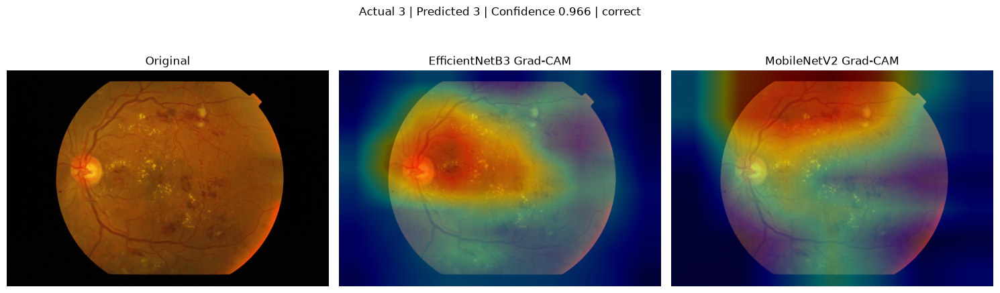

Processing 4da2961e62fe | actual=1 | predicted=1


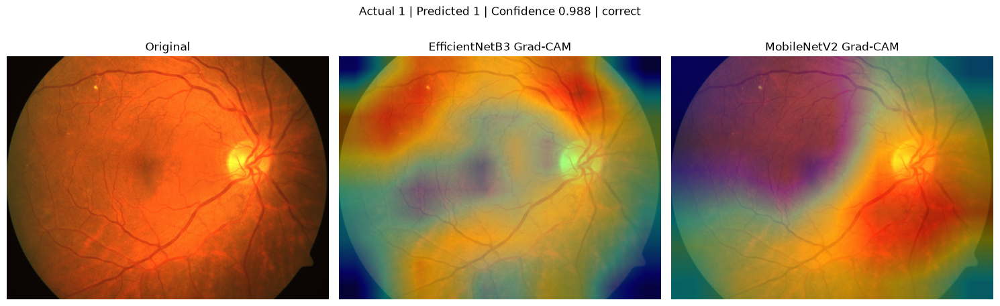

Processing a81b06f50612 | actual=4 | predicted=4


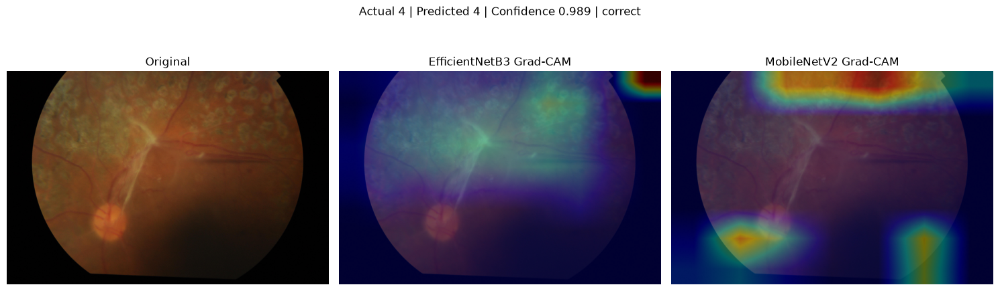

Processing f2ee81781411 | actual=2 | predicted=2


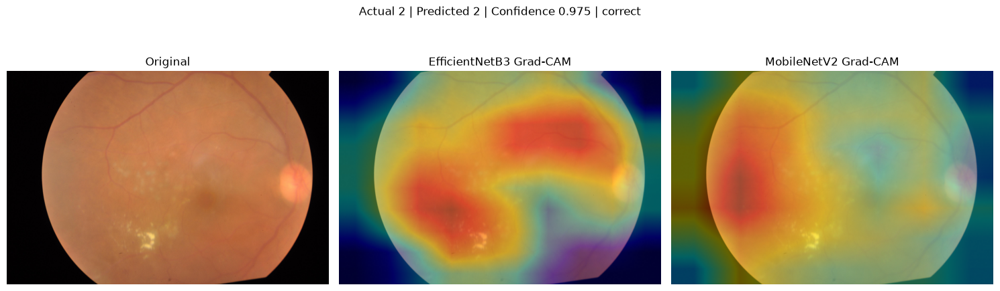

Processing 1e7ccd4a1c87 | actual=0 | predicted=0


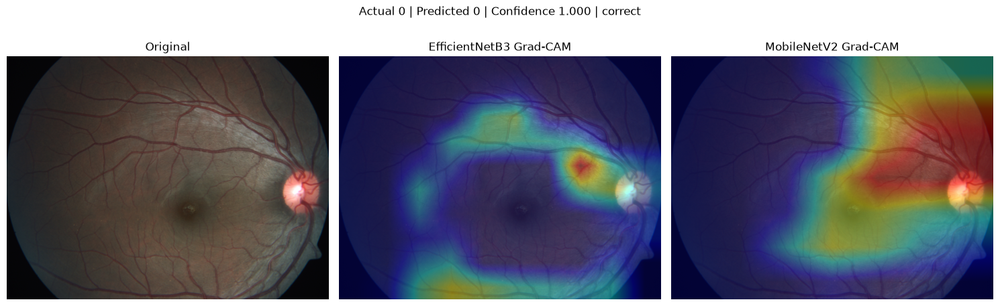

Processing 7a6e384a0846 | actual=3 | predicted=1


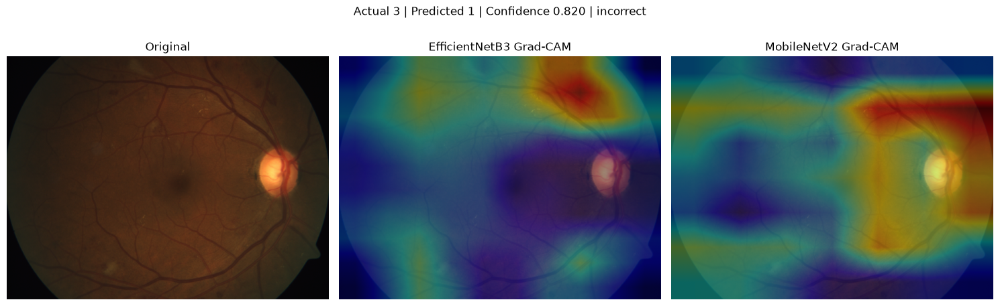

Processing 5b804948e35f | actual=1 | predicted=0


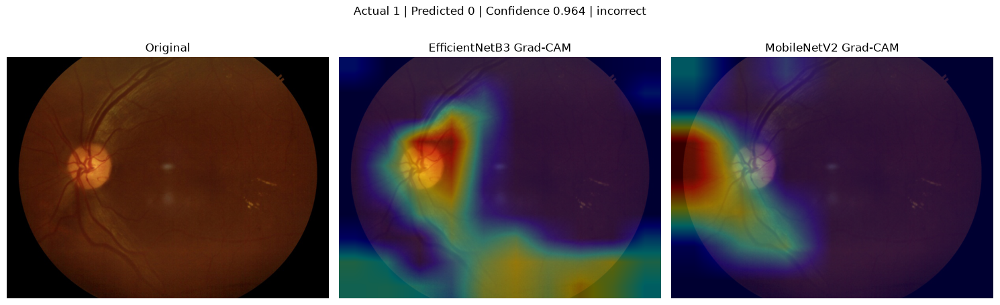

Processing 262ad704319c | actual=4 | predicted=3


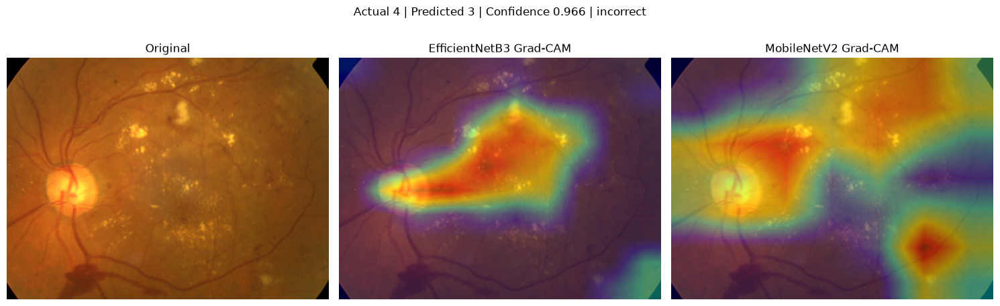

Processing eae901557a84 | actual=2 | predicted=1


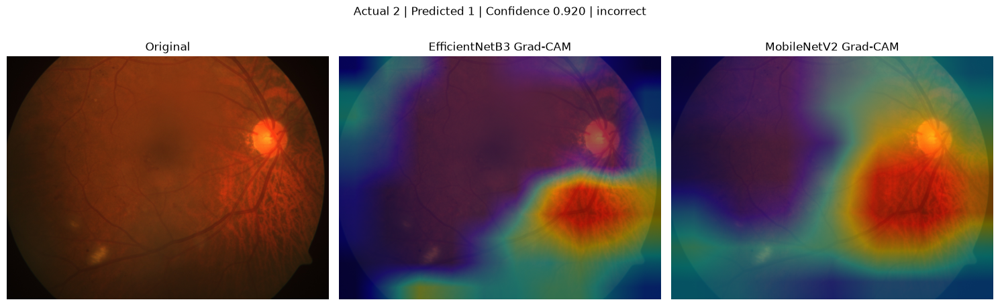

Processing ae5d31979f19 | actual=0 | predicted=1


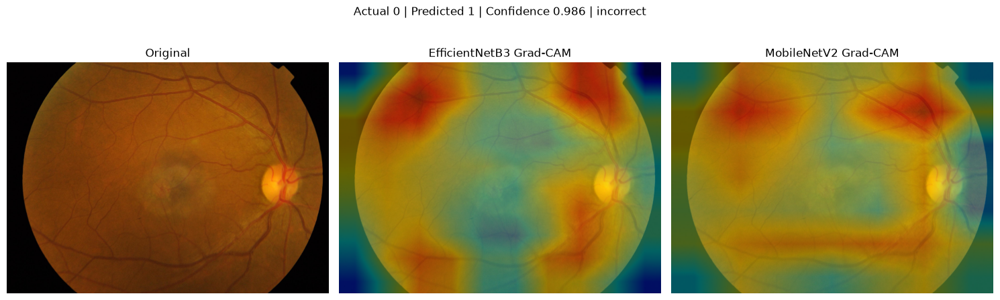

,id_code,actual,predicted,confidence,correct,saved_image
0,537e50fdf22e,3,3,0.965811,True,S:\ISP\data\processed\results\gradcam\537e50fd...
1,4da2961e62fe,1,1,0.987944,True,S:\ISP\data\processed\results\gradcam\4da2961e...
2,a81b06f50612,4,4,0.989025,True,S:\ISP\data\processed\results\gradcam\a81b06f5...
3,f2ee81781411,2,2,0.974996,True,S:\ISP\data\processed\results\gradcam\f2ee8178...
4,1e7ccd4a1c87,0,0,0.999967,True,S:\ISP\data\processed\results\gradcam\1e7ccd4a...
5,7a6e384a0846,3,1,0.819633,False,S:\ISP\data\processed\results\gradcam\7a6e384a...
6,5b804948e35f,1,0,0.963660,False,S:\ISP\data\processed\results\gradcam\5b804948...
7,262ad704319c,4,3,0.965839,False,S:\ISP\data\processed\results\gradcam\262ad704...
8,eae901557a84,2,1,0.920436,False,S:\ISP\data\processed\results\gradcam\eae90155...
9,ae5d31979f19,0,1,0.985679,False,S:\ISP\data\processed\results\gradcam\ae5d3197...


In [10]:
records = []
for _, row in selected_df.iterrows():
    print(f"Processing {row.id_code} | actual={int(row.diagnosis)} | predicted={int(row.predicted)}")
    records.append(save_gradcam_panel(row))

gradcam_summary = pd.DataFrame(records)
gradcam_summary.to_csv(RESULT_DIR / "gradcam_selected_examples.csv", index=False)
display(gradcam_summary)

## 11. Additional examples for the weakest class (class 3)

Class 3 examples: 5


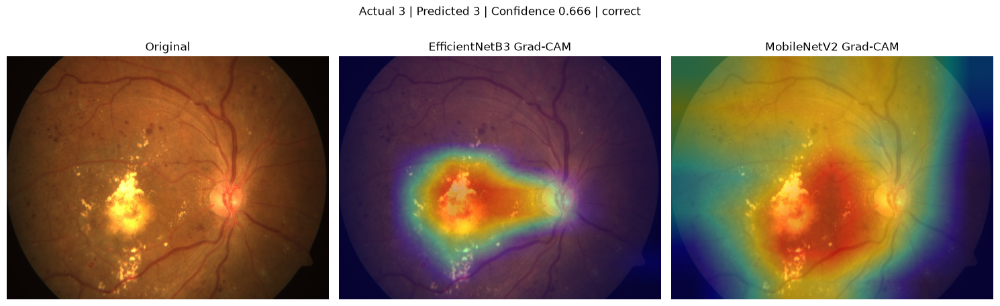

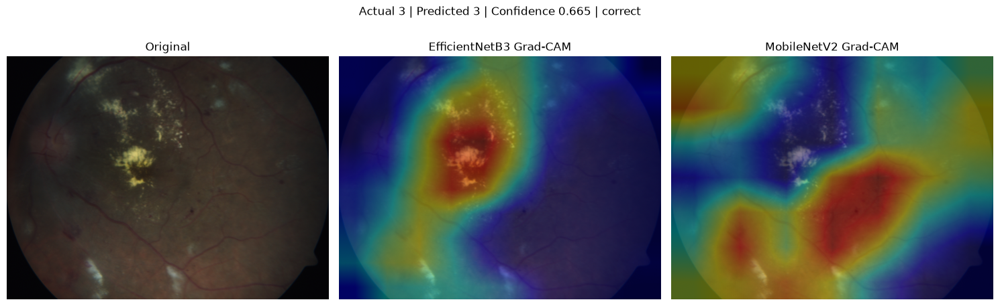

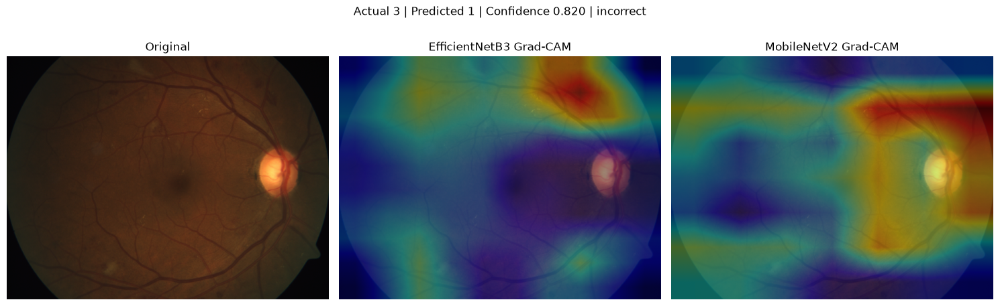

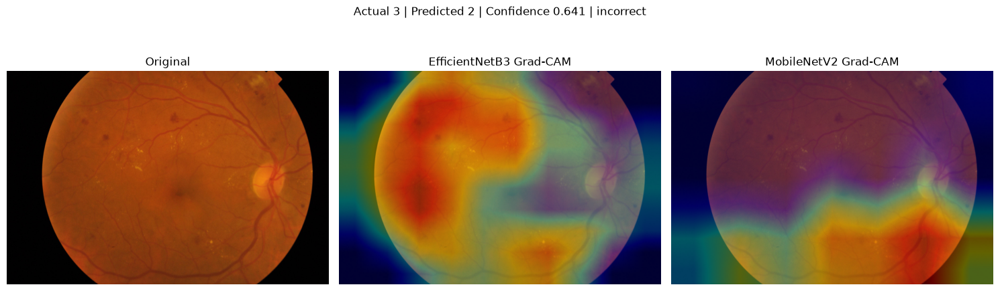

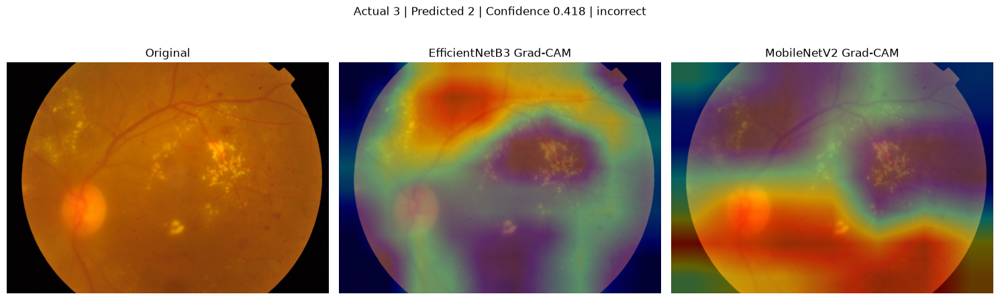

In [11]:
weak_class = 3
weak_correct = val_df[(val_df.diagnosis == weak_class) & val_df.correct].head(2)
weak_wrong = val_df[(val_df.diagnosis == weak_class) & (~val_df.correct)].head(3)
weak_df = pd.concat([weak_correct, weak_wrong]).drop_duplicates("id_code")
print("Class 3 examples:", len(weak_df))
for _, row in weak_df.iterrows():
    save_gradcam_panel(row)

## 12. Display saved Grad-CAM gallery

Saved Grad-CAM panels: 14


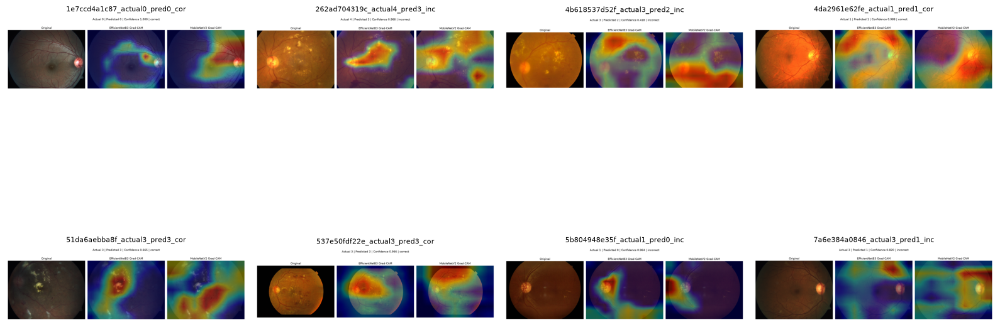

In [12]:
gallery = sorted(GRADCAM_DIR.glob("*.png"))
print("Saved Grad-CAM panels:", len(gallery))
if gallery:
    plt.figure(figsize=(16, 10))
    for i, path in enumerate(gallery[:8], 1):
        im = cv2.imread(str(path))
        im = cv2.cvtColor(im, cv2.COLOR_BGR2RGB)
        plt.subplot(2, 4, i)
        plt.imshow(im)
        plt.title(path.name[:30], fontsize=8)
        plt.axis("off")
    plt.tight_layout()
    plt.show()

## 13. Save Grad-CAM metadata and verify outputs

In [13]:
metadata = {
    "model": MODEL_PATH.name,
    "validation_images": int(len(val_df)),
    "reproduced_validation_accuracy": float(accuracy_score(val_df.diagnosis, val_df.predicted)),
    "efficientnet_target_layer": eff_conv.name,
    "mobilenet_target_layer": mob_conv.name,
    "output_folder": str(GRADCAM_DIR),
    "note": "Grad-CAM highlights influential image regions for a class score; it is not a clinical explanation."
}
with open(RESULT_DIR / "gradcam_metadata.json", "w") as f:
    json.dump(metadata, f, indent=4)

print(json.dumps(metadata, indent=4))
print("\nFiles:")
for p in sorted(RESULT_DIR.glob("gradcam*")):
    print(p.name)
print("Grad-CAM image count:", len(list(GRADCAM_DIR.glob("*.png"))))

{
    "model": "hybrid_optimized_focal.keras",
    "validation_images": 733,
    "reproduced_validation_accuracy": 0.781718963165075,
    "efficientnet_target_layer": "top_conv",
    "mobilenet_target_layer": "Conv_1",
    "output_folder": "S:\\ISP\\data\\processed\\results\\gradcam",
    "note": "Grad-CAM highlights influential image regions for a class score; it is not a clinical explanation."
}

Files:
gradcam
gradcam_metadata.json
gradcam_selected_examples.csv
Grad-CAM image count: 14


## Interpretation and limitations

- Heatmaps show regions that influence the selected class score under this Grad-CAM implementation; they do not prove that the highlighted region is medically meaningful.
- Review both correct and incorrect predictions.
- The validation set has already been used for model selection, so this analysis is exploratory.
- Do not describe Grad-CAM as clinical validation.
- Next: Notebook 10 consolidates metrics and prepares the selected model for frontend/backend integration.